In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# ============ 1. Imports and configuration ============
import os, random, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, roc_curve, auc, roc_auc_score)
from sklearn.preprocessing import label_binarize

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- Hyperparameters (report these in your document) ----
IMG_SIZE   = 160          # images resized to 160 x 160
BATCH_SIZE = 32
VAL_SPLIT  = 0.15         # 15% of TRAIN folder used as validation
EPOCHS_CNN = 25
EPOCHS_TL_HEAD = 8        # transfer learning phase 1 (frozen base)
EPOCHS_TL_FT   = 12       # transfer learning phase 2 (fine-tuning)
LR_CNN, LR_HEAD, LR_FT = 1e-3, 1e-3, 1e-5

OUT_DIR = "/kaggle/working"
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [5]:
# ============ 2. Download and locate the dataset ============
import os
# !pip install -q kagglehub     # uncomment if kagglehub is missing (e.g. Colab)
import kagglehub

path = kagglehub.dataset_download("paultimothymooney/blood-cells")
print("Path to dataset files:", path)

def find_split_dirs(base):
    for root, dirs, files in os.walk(base):
        low = {d.lower(): d for d in dirs}
        if "train" in low and "test" in low:
            return root, os.path.join(root, low["train"]), os.path.join(root, low["test"])
    raise FileNotFoundError("TRAIN/TEST folders not found under: " + base)

DATA_ROOT, TRAIN_DIR, TEST_DIR = find_split_dirs(path)
print("Dataset root:", DATA_ROOT)
print("Classes:", sorted(os.listdir(TRAIN_DIR)))

Path to dataset files: /kaggle/input/datasets/paultimothymooney/blood-cells
Dataset root: /kaggle/input/datasets/paultimothymooney/blood-cells/dataset2-master/dataset2-master/images
Classes: ['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL']


split       TEST  TRAIN
class                  
EOSINOPHIL   623   2497
LYMPHOCYTE   620   2483
MONOCYTE     620   2478
NEUTROPHIL   624   2499
Total images: 12444


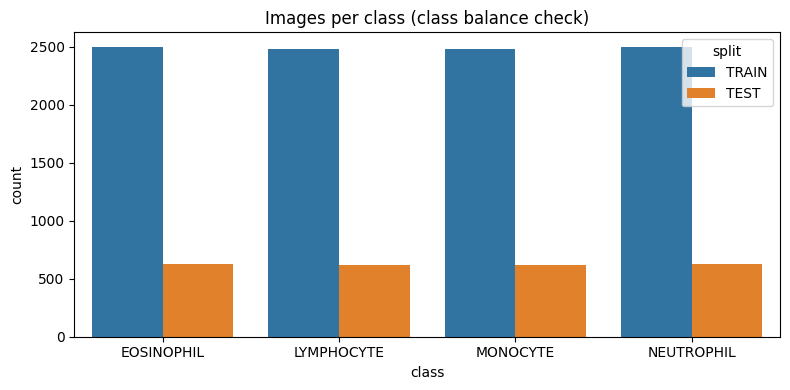

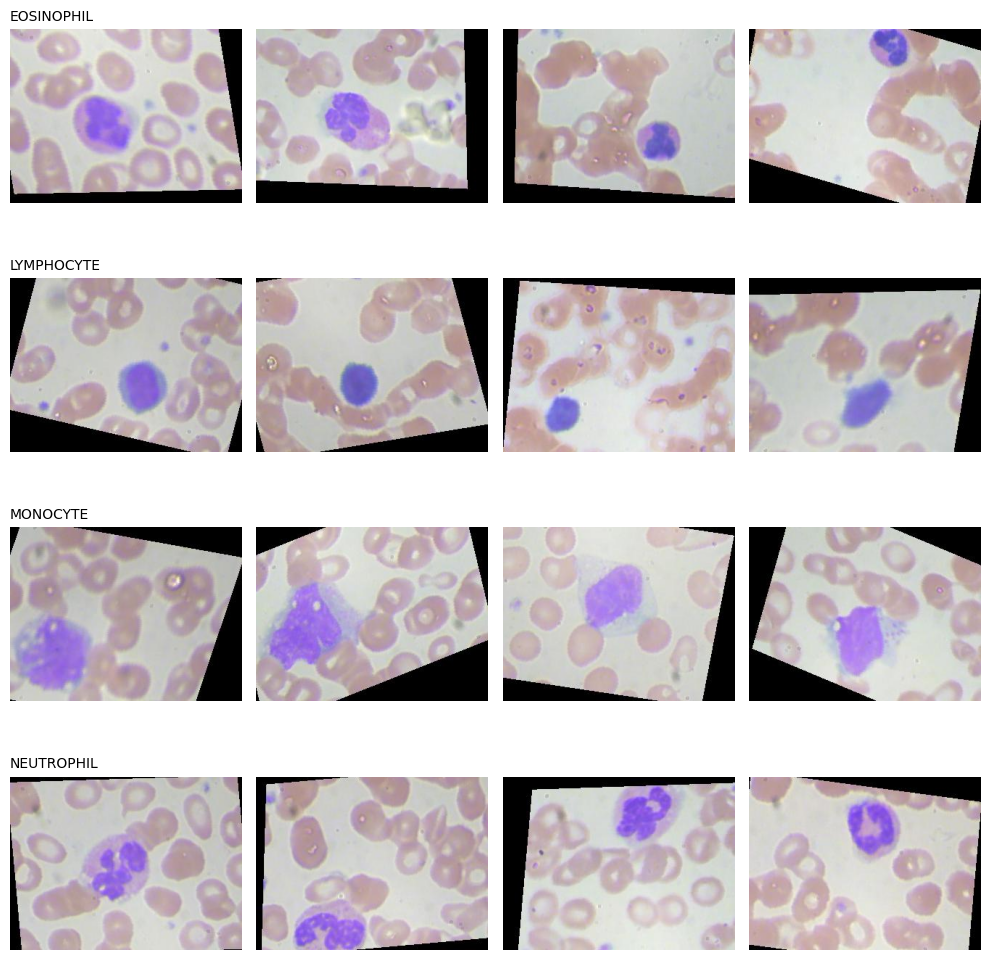

Original image shape example: (240, 320, 3)


In [6]:
# ============ 3. Data exploration ============
def count_images(folder):
    rows = []
    for cls in sorted(os.listdir(folder)):
        p = os.path.join(folder, cls)
        if os.path.isdir(p):
            rows.append((cls, len([f for f in os.listdir(p) if f.lower().endswith((".jpg", ".jpeg", ".png"))])))
    return pd.DataFrame(rows, columns=["class", "count"])

df_train = count_images(TRAIN_DIR); df_train["split"] = "TRAIN"
df_test  = count_images(TEST_DIR);  df_test["split"]  = "TEST"
df_counts = pd.concat([df_train, df_test])
print(df_counts.pivot(index="class", columns="split", values="count"))
print("Total images:", df_counts["count"].sum())

plt.figure(figsize=(8, 4))
sns.barplot(data=df_counts, x="class", y="count", hue="split")
plt.title("Images per class (class balance check)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/class_distribution.png", dpi=150); plt.show()

# Sample images
classes = sorted(os.listdir(TRAIN_DIR))
fig, axes = plt.subplots(len(classes), 4, figsize=(10, 2.6 * len(classes)))
for i, cls in enumerate(classes):
    files = random.sample(os.listdir(os.path.join(TRAIN_DIR, cls)), 4)
    for j, f in enumerate(files):
        img = plt.imread(os.path.join(TRAIN_DIR, cls, f))
        axes[i, j].imshow(img); axes[i, j].axis("off")
        if j == 0: axes[i, j].set_title(cls, loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/sample_images.png", dpi=150); plt.show()
print("Original image shape example:", img.shape)

In [7]:
# ============ 4. Build tf.data pipelines (train / validation / test) ============
common = dict(image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode="int")

train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=VAL_SPLIT, subset="training", seed=SEED, **common)
val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=VAL_SPLIT, subset="validation", seed=SEED, **common)
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR, shuffle=False, **common)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Class names:", class_names)

n_train = int(tf.data.experimental.cardinality(train_ds)) * BATCH_SIZE
n_val   = int(tf.data.experimental.cardinality(val_ds)) * BATCH_SIZE
n_test  = int(tf.data.experimental.cardinality(test_ds)) * BATCH_SIZE
print(f"Approx. batches x size -> train {n_train}, val {n_val}, test {n_test}")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 9957 files belonging to 4 classes.
Using 8464 files for training.
Found 9957 files belonging to 4 classes.
Using 1493 files for validation.
Found 2487 files belonging to 4 classes.
Class names: ['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL']
Approx. batches x size -> train 8480, val 1504, test 2496


In [8]:
# ============ 5. Preprocessing, augmentation and model definitions ============
# Preprocessing: resize to 160x160 (done in the loader) + pixel scaling inside each model.
# Augmentation (active only during training): flips, small rotation, zoom, contrast.
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")

# ---------- Model A: custom CNN from scratch ----------
def build_cnn():
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Rescaling(1.0 / 255)(x)
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="custom_cnn")

# ---------- Model B: MobileNetV2 transfer learning ----------
def build_mobilenet():
    try:
        base = keras.applications.MobileNetV2(
            input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
    except Exception as e:
        print("Could not download ImageNet weights. Turn Internet ON in Kaggle notebook settings.")
        raise e
    base.trainable = False
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)    # MobileNetV2 expects inputs in [-1, 1]
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="mobilenetv2_tl"), base

cnn_model = build_cnn()
cnn_model.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 20, 20, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 20, 20, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 423,268 (1.61 MB)

 Trainable params: 422,308 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [9]:
# ============ 6. Train Model A: custom CNN ============
cnn_model.compile(optimizer=keras.optimizers.Adam(LR_CNN),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

callbacks_cnn = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
]
t0 = time.time()
hist_cnn = cnn_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_CNN,
                         callbacks=callbacks_cnn, verbose=2)
time_cnn = time.time() - t0
print(f"CNN training time: {time_cnn/60:.1f} min")
cnn_model.save(f"{OUT_DIR}/custom_cnn.keras")
hist_cnn = hist_cnn.history

Epoch 1/25
265/265 - 185s - 698ms/step - accuracy: 0.5533 - loss: 1.0043 - val_accuracy: 0.2559 - val_loss: 2.7893 - learning_rate: 0.0010
Epoch 2/25
265/265 - 20s - 74ms/step - accuracy: 0.8414 - loss: 0.4131 - val_accuracy: 0.2492 - val_loss: 16.7166 - learning_rate: 0.0010
Epoch 3/25
265/265 - 19s - 73ms/step - accuracy: 0.8940 - loss: 0.2758 - val_accuracy: 0.6142 - val_loss: 2.8845 - learning_rate: 0.0010
Epoch 4/25

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
265/265 - 19s - 72ms/step - accuracy: 0.9088 - loss: 0.2365 - val_accuracy: 0.3885 - val_loss: 6.4725 - learning_rate: 0.0010
Epoch 5/25
265/265 - 19s - 72ms/step - accuracy: 0.9428 - loss: 0.1608 - val_accuracy: 0.7200 - val_loss: 1.0268 - learning_rate: 5.0000e-04
Epoch 6/25
265/265 - 19s - 72ms/step - accuracy: 0.9458 - loss: 0.1481 - val_accuracy: 0.9143 - val_loss: 0.2427 - learning_rate: 5.0000e-04
Epoch 7/25
265/265 - 19s - 73ms/step - accuracy: 0.9524 - loss: 0.1341 - val_accuracy: 0.3

In [11]:
# ============ 7. Train Model B: MobileNetV2 (phase 1 head, phase 2 fine-tune) ============
tl_model, base = build_mobilenet()

# Phase 1: train only the new classification head
tl_model.compile(optimizer=keras.optimizers.Adam(LR_HEAD),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
h1 = tl_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_TL_HEAD, verbose=2)

# Phase 2: unfreeze the top 30 layers of the base network, use a very small learning rate
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
tl_model.compile(optimizer=keras.optimizers.Adam(LR_FT),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
callbacks_tl = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
]
h2 = tl_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_TL_FT,
                  callbacks=callbacks_tl, verbose=2)
time_tl = time.time() - t0
print(f"MobileNetV2 training time: {time_tl/60:.1f} min")
tl_model.save(f"{OUT_DIR}/mobilenetv2_tl.keras")

hist_tl = {k: h1.history[k] + h2.history[k] for k in h1.history}
phase1_epochs = len(h1.history["loss"])

Epoch 1/8
265/265 - 16s - 60ms/step - accuracy: 0.4503 - loss: 1.3085 - val_accuracy: 0.5874 - val_loss: 0.9811
Epoch 2/8
265/265 - 10s - 38ms/step - accuracy: 0.5826 - loss: 1.0028 - val_accuracy: 0.5854 - val_loss: 0.9324
Epoch 3/8
265/265 - 10s - 38ms/step - accuracy: 0.6173 - loss: 0.9155 - val_accuracy: 0.5767 - val_loss: 0.9342
Epoch 4/8
265/265 - 10s - 38ms/step - accuracy: 0.6323 - loss: 0.8764 - val_accuracy: 0.6497 - val_loss: 0.8473
Epoch 5/8
265/265 - 10s - 38ms/step - accuracy: 0.6486 - loss: 0.8550 - val_accuracy: 0.6510 - val_loss: 0.8555
Epoch 6/8
265/265 - 10s - 37ms/step - accuracy: 0.6654 - loss: 0.8275 - val_accuracy: 0.6591 - val_loss: 0.7978
Epoch 7/8
265/265 - 10s - 37ms/step - accuracy: 0.6576 - loss: 0.8334 - val_accuracy: 0.6417 - val_loss: 0.8605
Epoch 8/8
265/265 - 10s - 38ms/step - accuracy: 0.6543 - loss: 0.8381 - val_accuracy: 0.6557 - val_loss: 0.8152
Epoch 1/12
265/265 - 22s - 85ms/step - accuracy: 0.5441 - loss: 1.4060 - val_accuracy: 0.5553 - val_loss

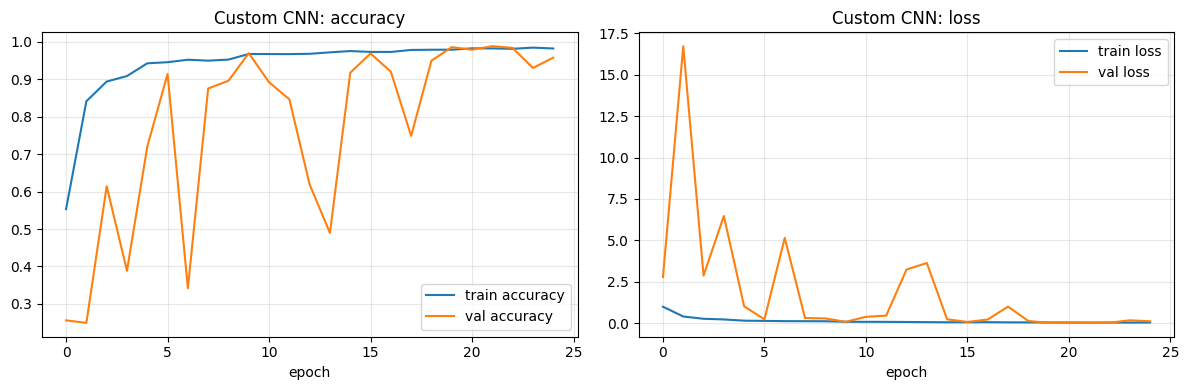

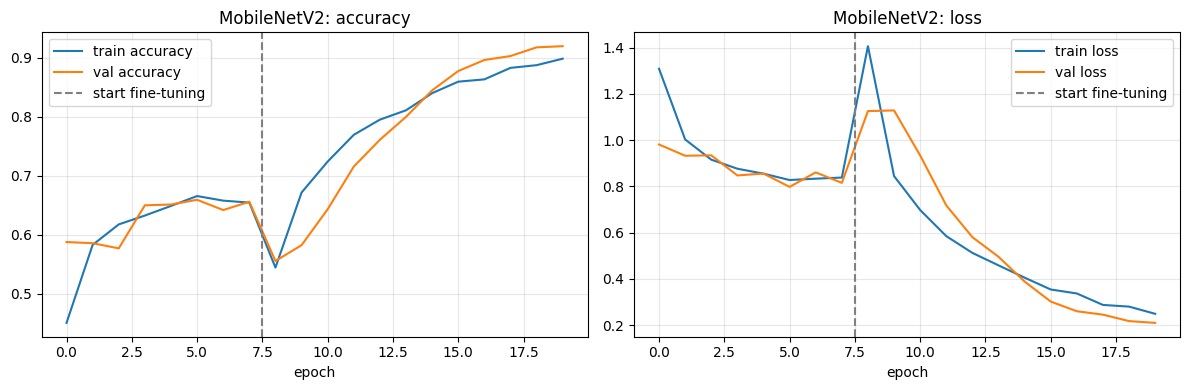

In [12]:
# ============ 8. Training / validation curves ============
def plot_history(hist, title, fname, split_at=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, m in zip(ax, ["accuracy", "loss"]):
        a.plot(hist[m], label=f"train {m}")
        a.plot(hist[f"val_{m}"], label=f"val {m}")
        if split_at: a.axvline(split_at - 0.5, color="gray", ls="--", label="start fine-tuning")
        a.set_title(f"{title}: {m}"); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{fname}", dpi=150); plt.show()

plot_history(hist_cnn, "Custom CNN", "curves_cnn.png")
plot_history(hist_tl, "MobileNetV2", "curves_mobilenet.png", split_at=phase1_epochs)


===== Custom_CNN =====
Test accuracy: 0.8846 | Macro F1: 0.8876 | Macro ROC-AUC: 0.9905
              precision    recall  f1-score   support

  EOSINOPHIL     0.9272    0.8379    0.8803       623
  LYMPHOCYTE     1.0000    1.0000    1.0000       620
    MONOCYTE     1.0000    0.7661    0.8676       620
  NEUTROPHIL     0.7033    0.9343    0.8025       624

    accuracy                         0.8846      2487
   macro avg     0.9076    0.8846    0.8876      2487
weighted avg     0.9073    0.8846    0.8874      2487



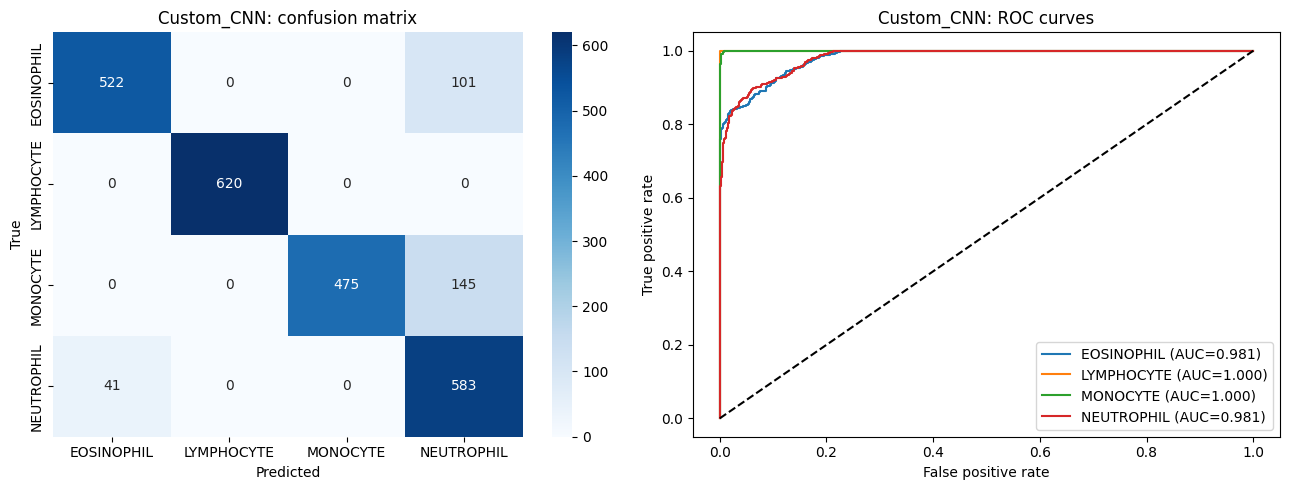


===== MobileNetV2 =====
Test accuracy: 0.6550 | Macro F1: 0.6470 | Macro ROC-AUC: 0.8878
              precision    recall  f1-score   support

  EOSINOPHIL     0.4770    0.6148    0.5372       623
  LYMPHOCYTE     0.7615    0.9113    0.8297       620
    MONOCYTE     0.7402    0.3952    0.5152       620
  NEUTROPHIL     0.7136    0.6987    0.7061       624

    accuracy                         0.6550      2487
   macro avg     0.6730    0.6550    0.6470      2487
weighted avg     0.6729    0.6550    0.6470      2487



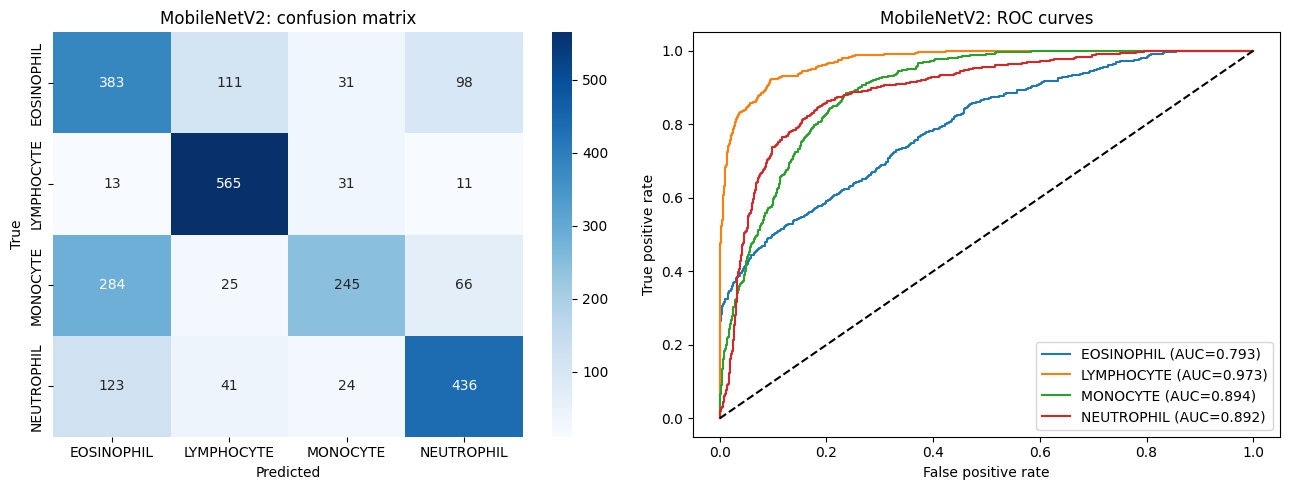

In [13]:
# ============ 9. Evaluation on the held-out TEST set ============
y_true = np.concatenate([y.numpy() for _, y in test_ds])
results = {}

def evaluate_model(model, name, train_time):
    probs = model.predict(test_ds, verbose=0)
    y_pred = probs.argmax(axis=1)
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro")
    y_bin = label_binarize(y_true, classes=range(NUM_CLASSES))
    auc_macro = roc_auc_score(y_bin, probs, average="macro", multi_class="ovr")
    results[name] = dict(accuracy=acc, macro_f1=f1m, roc_auc_macro=auc_macro,
                         parameters=model.count_params(), train_minutes=train_time / 60)

    print(f"\n===== {name} =====")
    print(f"Test accuracy: {acc:.4f} | Macro F1: {f1m:.4f} | Macro ROC-AUC: {auc_macro:.4f}")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names,
                yticklabels=class_names, ax=ax[0])
    ax[0].set_title(f"{name}: confusion matrix"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")

    # ROC curves (one-vs-rest)
    for i, cls in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
        ax[1].plot(fpr, tpr, label=f"{cls} (AUC={auc(fpr, tpr):.3f})")
    ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title(f"{name}: ROC curves")
    ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend()
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/eval_{name}.png", dpi=150); plt.show()
    return probs, y_pred

probs_cnn, pred_cnn = evaluate_model(cnn_model, "Custom_CNN", time_cnn)
probs_tl,  pred_tl  = evaluate_model(tl_model,  "MobileNetV2", time_tl)

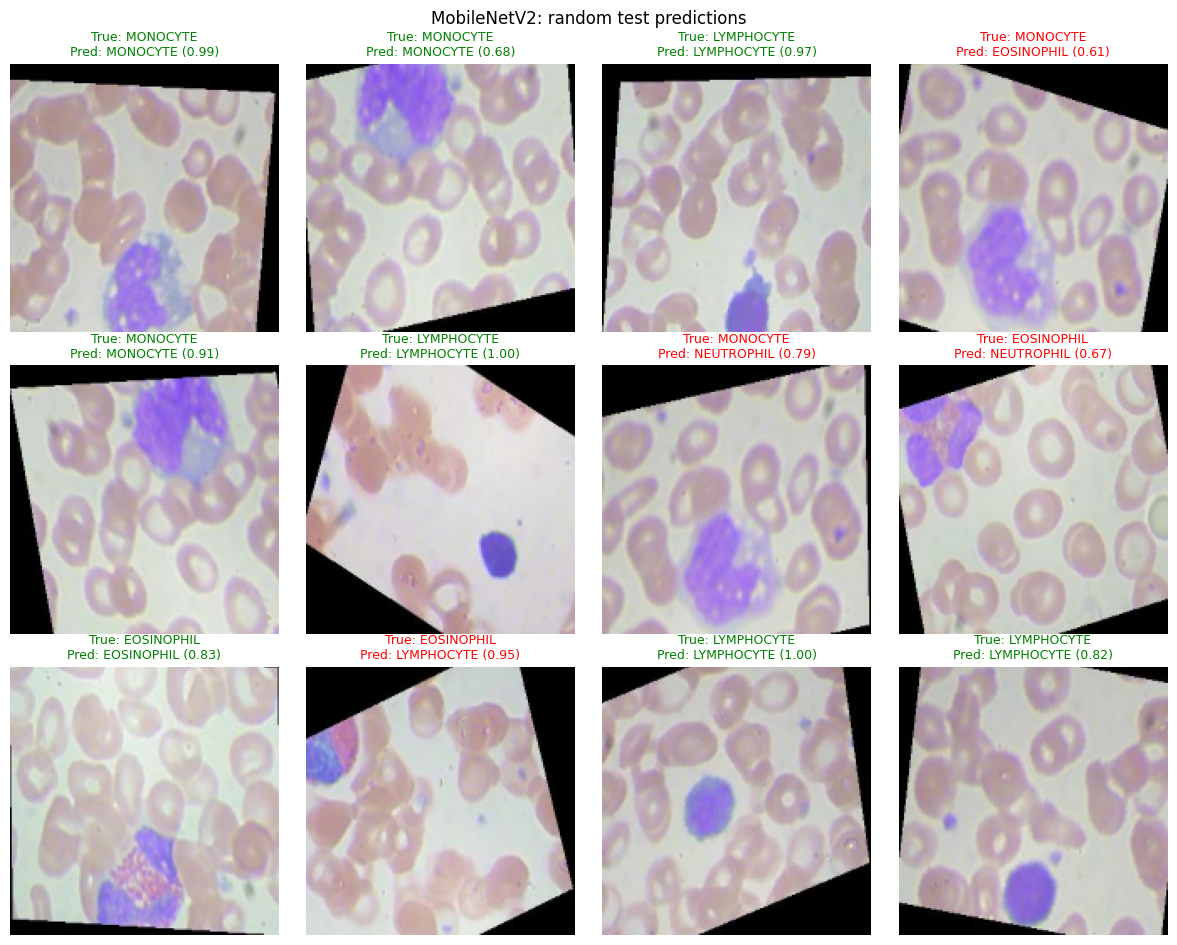

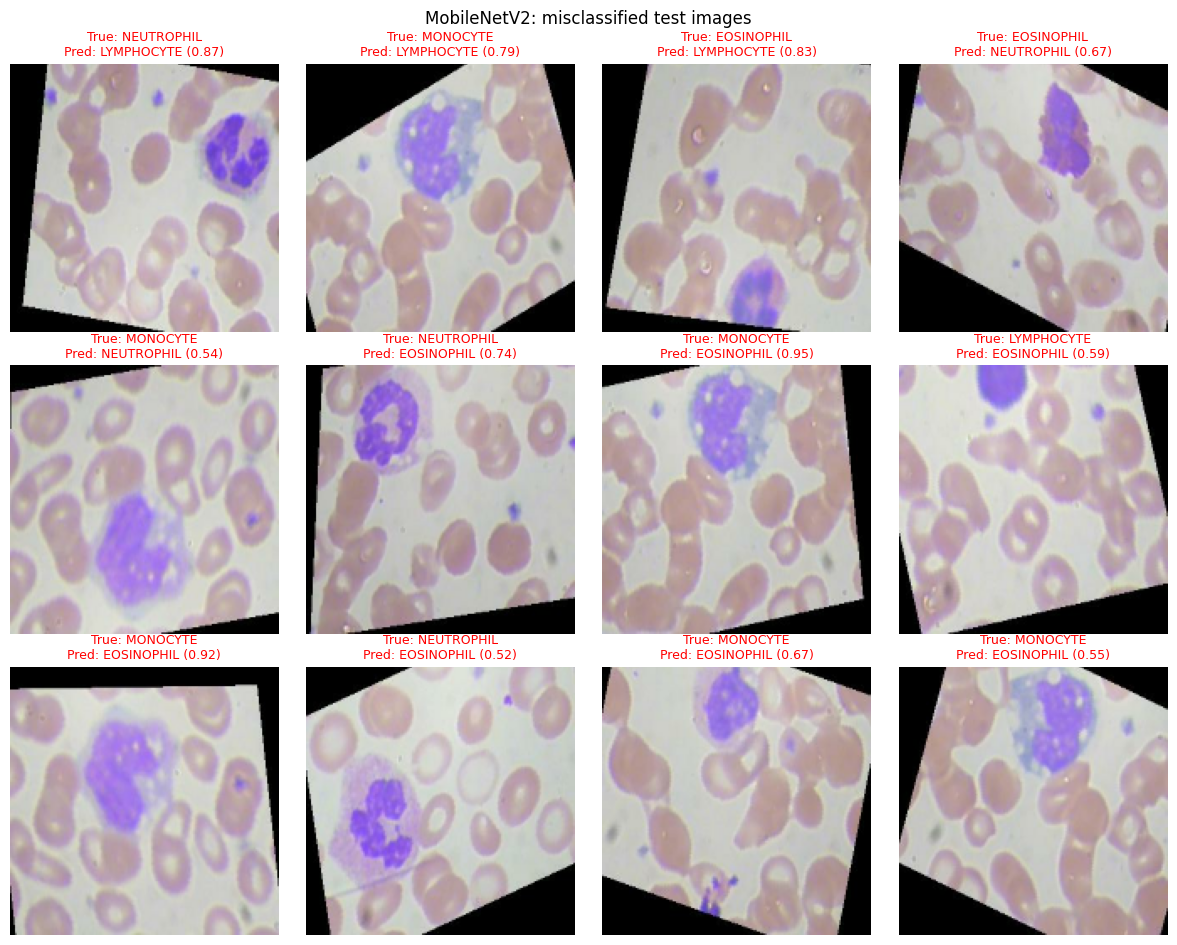

In [14]:
# ============ 10. Prediction examples and error analysis ============
images_all = np.concatenate([x.numpy().astype("uint8") for x, _ in test_ds])

def show_predictions(pred, probs, title, fname, only_wrong=False, n=12):
    idx = np.where(pred != y_true)[0] if only_wrong else np.arange(len(y_true))
    if len(idx) == 0:
        print("No misclassified samples."); return
    idx = np.random.RandomState(SEED).choice(idx, size=min(n, len(idx)), replace=False)
    cols = 4; rows = int(np.ceil(len(idx) / cols))
    plt.figure(figsize=(12, 3.2 * rows))
    for k, i in enumerate(idx):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(images_all[i]); plt.axis("off")
        ok = pred[i] == y_true[i]
        plt.title(f"True: {class_names[y_true[i]]}\nPred: {class_names[pred[i]]} ({probs[i].max():.2f})",
                  color="green" if ok else "red", fontsize=9)
    plt.suptitle(title); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{fname}", dpi=150); plt.show()

show_predictions(pred_tl, probs_tl, "MobileNetV2: random test predictions", "pred_examples.png")
show_predictions(pred_tl, probs_tl, "MobileNetV2: misclassified test images", "misclassified.png", only_wrong=True)

             accuracy  macro_f1  roc_auc_macro  parameters  train_minutes
Custom_CNN     0.8846    0.8876         0.9905    423268.0        10.7575
MobileNetV2    0.6550    0.6470         0.8878   2263108.0         4.2095


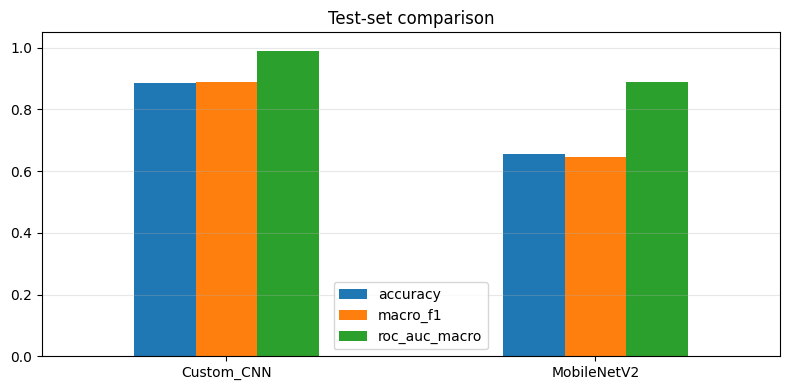

In [15]:
# ============ 11. Model comparison table ============
df_res = pd.DataFrame(results).T.round(4)
print(df_res)
df_res.to_csv(f"{OUT_DIR}/model_comparison.csv")

df_res[["accuracy", "macro_f1", "roc_auc_macro"]].plot(kind="bar", figsize=(8, 4), ylim=(0, 1.05))
plt.title("Test-set comparison"); plt.xticks(rotation=0); plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/model_comparison.png", dpi=150); plt.show()

# Save run configuration for the report
with open(f"{OUT_DIR}/config.json", "w") as f:
    json.dump(dict(IMG_SIZE=IMG_SIZE, BATCH_SIZE=BATCH_SIZE, VAL_SPLIT=VAL_SPLIT, SEED=SEED,
                   EPOCHS_CNN=EPOCHS_CNN, EPOCHS_TL_HEAD=EPOCHS_TL_HEAD, EPOCHS_TL_FT=EPOCHS_TL_FT,
                   LR_CNN=LR_CNN, LR_HEAD=LR_HEAD, LR_FT=LR_FT,
                   optimizer="Adam", loss="sparse_categorical_crossentropy"), f, indent=2)

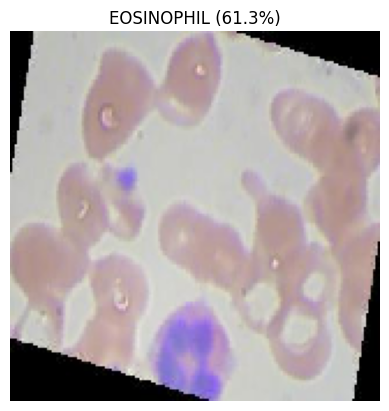

{'EOSINOPHIL': np.float32(0.613), 'LYMPHOCYTE': np.float32(0.1773), 'MONOCYTE': np.float32(0.0588), 'NEUTROPHIL': np.float32(0.1508)}


In [16]:
# ============ 12. Predict a single image (demo for the viva) ============
def predict_image(path, model=tl_model):
    img = keras.utils.load_img(path, target_size=(IMG_SIZE, IMG_SIZE))
    arr = np.expand_dims(keras.utils.img_to_array(img), 0)
    p = model.predict(arr, verbose=0)[0]
    plt.imshow(img); plt.axis("off")
    plt.title(f"{class_names[p.argmax()]} ({p.max()*100:.1f}%)"); plt.show()
    return dict(zip(class_names, p.round(4)))

# Example: pick any image from the test folder
sample_cls = class_names[0]
sample_path = os.path.join(TEST_DIR, sample_cls, os.listdir(os.path.join(TEST_DIR, sample_cls))[0])
print(predict_image(sample_path))